In [ ]:
pip install nltk beautifulsoup4 contractions emoji spacy
python -m nltk.downloader punkt stopwords averaged_perceptron_tagger wordnet omw-1.4 maxent_ne_chunker words
python -m spacy download en_core_web_sm

In [ ]:
# NLTK comes with several pre-built corpora that you can use for practice and research.


Features of NLTK
*Tokenization
* Stopword Removal
* Stemming
* Lemmatization
* POS (Part-of-Speech) Tagging
* Named Entity Recognition (basic support)
* Text Classification
* WordNet (English dictionary)
* Corpus (pre-built text datasets)

Features of SpaCy
* Fast Tokenization
* POS Tagging
* Named Entity Recognition (NER)
* Dependency Parsing
* Sentence Segmentation
* Word Vectors
* Text Classification
* Language Detection (with extensions)

In [ ]:
# ==========================================================
# NLP PREPROCESSING PIPELINE (WITH EXPLANATION)
# ==========================================================

# Import Regular Expression library (used for removing URLs, numbers, special characters)
import re

# Import NLTK library for NLP tasks
import nltk

# Import Emoji library to remove emojis
import emoji

# Import contractions library to convert short forms into full forms
import contractions

# Import SpaCy library for Named Entity Recognition
import spacy

# Import BeautifulSoup to remove HTML tags
from bs4 import BeautifulSoup

# Import tokenizer to split sentence into words
from nltk.tokenize import word_tokenize

# Import stopwords list (like is, am, the, etc.)
from nltk.corpus import stopwords

# Import Porter Stemmer for stemming
from nltk.stem import PorterStemmer

# Import WordNet Lemmatizer for lemmatization
from nltk.stem import WordNetLemmatizer

# Import POS Tagger
from nltk import pos_tag

# Load English model in SpaCy
nlp = spacy.load("en_core_web_sm")      # Loads the English NLP model

# ==========================================================
# INPUT TEXT
# ==========================================================

text = """
<p>Hello! 😊 I'm John, and I visited https://openai.com on 12/08/2026.
I can't believe AI is growing so fast!!!</p>
"""

print("Original Text")
print(text)

# ==========================================================
# STEP 1 : LOWERCASE CONVERSION
# ==========================================================

text = text.lower()      # Converts all uppercase letters into lowercase

print("\nLowercase Text")
print(text)

# ==========================================================
# STEP 2 : REMOVE HTML TAGS
# ==========================================================

text = BeautifulSoup(text, "html.parser").get_text()
# Removes HTML tags like <p>, <div>, <h1>

print("\nAfter Removing HTML")
print(text)

# ==========================================================
# STEP 3 : REMOVE URLS
# ==========================================================

text = re.sub(r'http\S+|www\S+', '', text)
# Removes URLs like https://google.com

print("\nAfter Removing URLs")
print(text)

# ==========================================================
# STEP 4 : REMOVE EMOJIS
# ==========================================================

text = emoji.replace_emoji(text, replace='')
# Removes emojis such as 😊😂🔥

print("\nAfter Removing Emojis")
print(text)

# ==========================================================
# STEP 5 : EXPAND CONTRACTIONS
# ==========================================================

text = contractions.fix(text)
# Converts:
# can't → cannot
# I'm → I am
# won't → will not

print("\nAfter Expanding Contractions")
print(text)

# ==========================================================
# STEP 6 : REMOVE SPECIAL CHARACTERS
# ==========================================================

text = re.sub(r'[^A-Z-0-9\s]', '', text)
# Removes punctuation and special characters
# Keeps only letters, numbers and spaces

print("\nAfter Removing Special Characters")
print(text)

# ==========================================================
# STEP 7 : REMOVE NUMBERS
# ==========================================================

text = re.sub(r'\d+', '', text)
# Removes all digits like 123, 2026, 45

print("\nAfter Removing Numbers")
print(text)

# ==========================================================
# STEP 8 : REMOVE EXTRA SPACES
# ==========================================================

text = re.sub(r'\s+', ' ', text).strip()
# Replaces multiple spaces with a single space

print("\nAfter Removing Extra Spaces")
print(text)

# ==========================================================
# STEP 9 : TOKENIZATION
# ==========================================================

tokens = word_tokenize(text)
# Splits the sentence into individual words

print("\nTokens")
print(tokens)

# ==========================================================
# STEP 10 : STOPWORD REMOVAL
# ==========================================================

stop_words = set(stopwords.words('english'))
# Loads English stopwords

filtered_words = [word for word in tokens if word not in stop_words]
# Removes words like:
# is
# am
# the
# and
# to
# on

print("\nAfter Stopword Removal")
print(filtered_words)

# ==========================================================
# STEP 11 : STEMMING
# ==========================================================

stemmer = PorterStemmer()
# Creates Porter Stemmer object

stemmed_words = [stemmer.stem(word) for word in filtered_words]
# Converts words to root form
# playing → play
# studying → studi
# visited → visit

print("\nStemmed Words")
print(stemmed_words)

# ==========================================================
# STEP 12 : LEMMATIZATION
# ==========================================================

lemmatizer = WordNetLemmatizer()
# Creates Lemmatizer object

lemmatized_words = [lemmatizer.lemmatize(word) for word in filtered_words]
# Converts words into dictionary base form
# playing → play
# studies → study
# mice → mouse

print("\nLemmatized Words")
print(lemmatized_words)

# ==========================================================
# STEP 13 : POS TAGGING
# ==========================================================

#POS Tagging tells us whether a word is a noun, verb, adjective, adverb, pronoun, etc.#

pos = pos_tag(lemmatized_words)
# Identifies the grammatical role of each word
# Example:
# NN = Noun
# VB = Verb
# JJ = Adjective

print("\nPOS Tags")
print(pos)

# ==========================================================
# STEP 14 : NAMED ENTITY RECOGNITION (NER)
# ==========================================================

doc = nlp(" ".join(lemmatized_words))
# Converts the list back into a sentence and processes it with SpaCy

print("\nNamed Entities")

for ent in doc.ents:
    print(ent.text, "-->", ent.label_)
    # Prints named entities
    # PERSON → John
    # ORG → Google
    # GPE → India
    # DATE → 12 August 2026

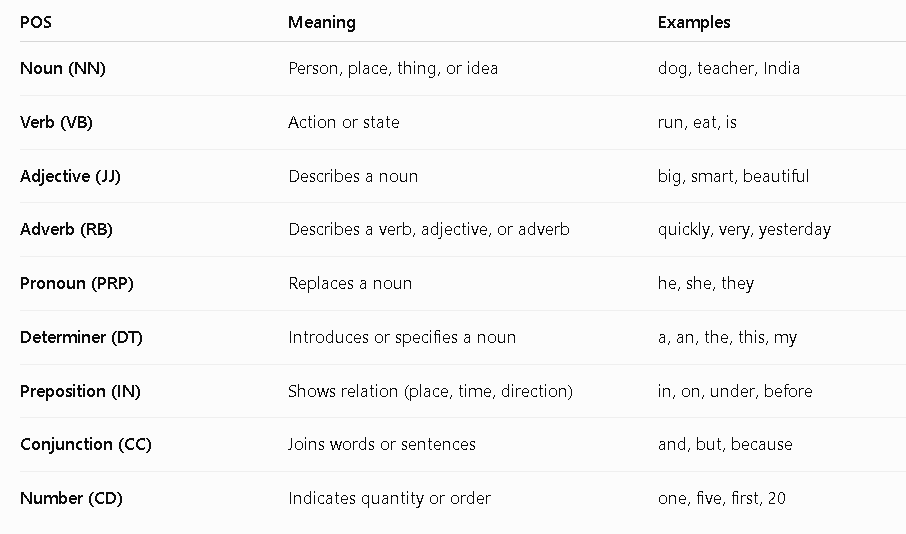

*NER*

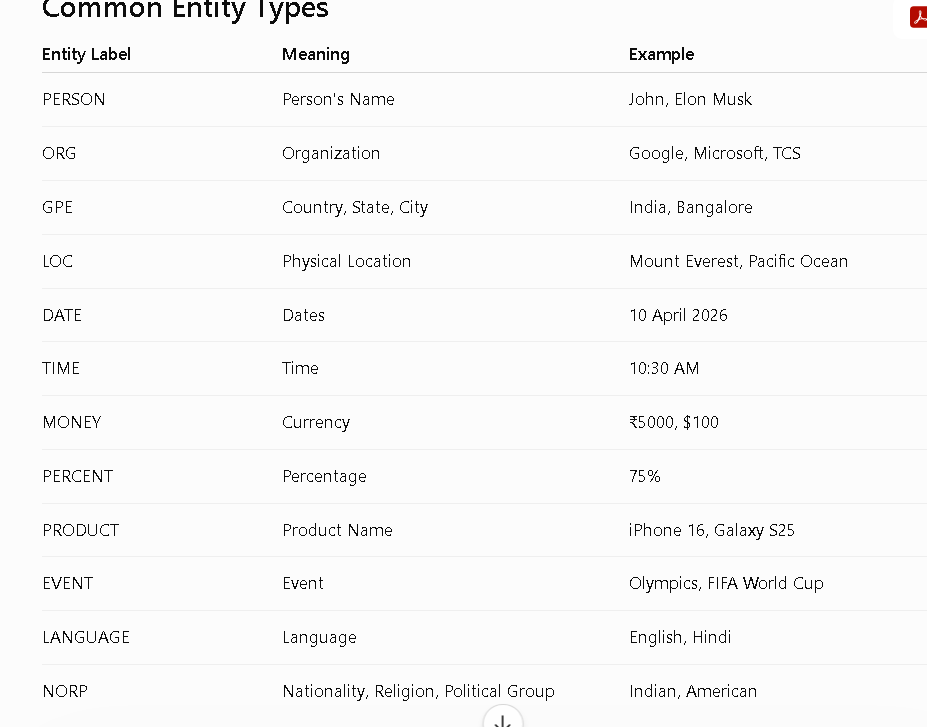

In [ ]:
# ==========================================================
# STEP 15 : BAG OF WORDS
# ==========================================================

from sklearn.feature_extraction.text import CountVectorizer

# Convert list back into sentence
clean_text = " ".join(lemmatized_words)

corpus = [clean_text]

bow = CountVectorizer()

bow_matrix = bow.fit_transform(corpus)

print("\nBag of Words Matrix")
print(bow_matrix.toarray())

print("\nVocabulary")
print(bow.get_feature_names_out())

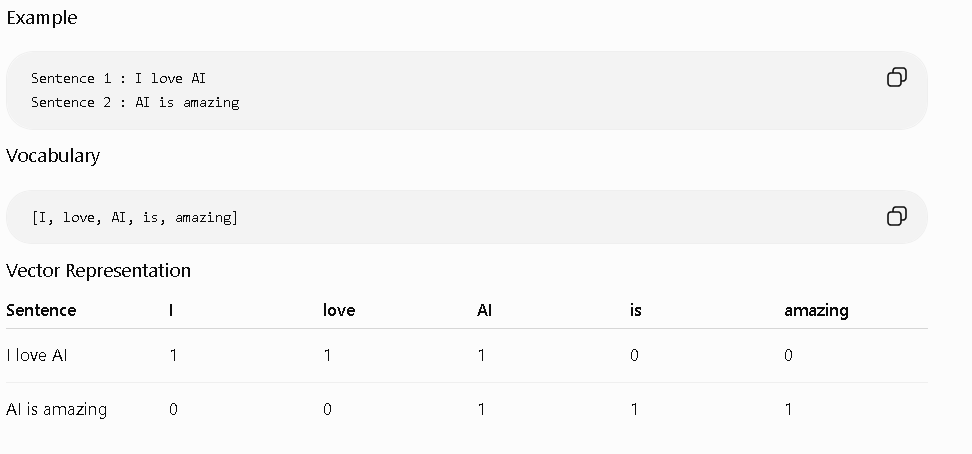

In [ ]:
# ==========================================================
# STEP 16 : TF-IDF
# ==========================================================

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()

tfidf_matrix = tfidf.fit_transform(corpus)

print("\nTF-IDF Features")

print(tfidf.get_feature_names_out())

print(tfidf_matrix.toarray())

In [ ]:
# ==========================================================
# STEP 17 : WORD2VEC
# ==========================================================

from gensim.models import Word2Vec

sentences = [lemmatized_words]

model = Word2Vec(
    sentences,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4
)

print("\nVector of 'ai'")

print(model.wv["ai"])